**Analysis of prefiltered dataset**

In [171]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from astropy.io import fits
import os
from photutils.background import Background2D, MedianBackground
from astropy.stats import SigmaClip

In [3]:
#Master BIAS
bias_dir = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\bias\\"
bias_files = os.listdir(bias_dir) #all files in directory
bias_images = [] #array that contains all bias images

for file in bias_files: #which datasets?
    image = fits.getdata(bias_dir+file)
    bias_images.append(image)

# Stack the Bias images using median
master_bias = np.median(np.asarray(bias_images), axis=0) #meridian is less sensitive to outliers

#save the master bias as fits file

savename = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\\" + "master_bias.fits"
fits.writeto(savename, master_bias, overwrite=True)

In [4]:
#Master FLATS
flat_dir = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\flats"
flat_folders = os.listdir(flat_dir) #all files in directory



#different filters
filters = ["black","green","red","blue"]
master_flats = {}

for filter in filters:
    flat_images = [] #array that contains all bias images
    flat_files = os.listdir(flat_dir + r"\\"+ filter)

    for file in flat_files: #which datasets?
        image = fits.getdata(flat_dir+ r"\\" +filter + r"\\" + file)
        flat_images.append(image)

    # Stack the flat images after normalizing to the median
    cflats = []
    for ic in range(len(flat_images)):
        cflats.append((flat_images[ic] - master_bias)/np.median(flat_images[ic]-master_bias))
    master_flat = np.median(cflats,axis=0)
    master_flats[filter] = master_flat


    #save the master flat
    fits.writeto(r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\\"+"master_flat_"+filter+".fits", master_flat, overwrite=True)


In [172]:
#CALIBRATE THE FIT FILES WITH BIAS AND FLAT

#function that deletes the background of an calibrated image:
def subtract_background(science_calibrated,master_bias,master_flat):
    #create mask that 
    mask=np.zeros(np.shape(science_calibrated))
    for i in range(len(science_calibrated)):
        for j in range(len(science_calibrated[i])):
            if master_flat[i][j]<0.2:
                science_calibrated[i][j]=0
                mask[i][j]=1
    mask=mask.astype(bool)

    sigma_clip = SigmaClip(sigma=3.0) #object used to cut out outliers out of 3sigma interval
    bkg_estimator = MedianBackground() #use the median as backround estimator, could also use the mean
    bkg = Background2D(science_calibrated,(50,50),filter_size=(13,13),sigma_clip=sigma_clip, bkg_estimator=bkg_estimator,coverage_mask=mask)

    return science_calibrated - bkg.background


    
#function that calibrates depending on filter extension in filename
#needs master_bias, master_flat_filter with filter=[black,green,blue,red]
def calibrate(filename,directory):
    data = fits.getdata(directory + r"\\"+ filename)
    filters = ["black","Red","Blue","Green"]
    flats_dict = {"black":master_flats["black"],"Red":master_flats["red"],"Blue":master_flats["blue"],"Green":master_flats["green"]}
    for filter in filters:
        if filter in filename:
            result = (data - master_bias)/flats_dict[filter]
            result = subtract_background(result,master_bias=master_bias,master_flat=flats_dict[filter]) #new, does it work?
            break
        else:
            result = None

    
    return result

#calibrate all data in directory
path = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\mag_calibration"
folders = os.listdir(path)
for dir in folders:
    if dir != "flats" and dir != "bias":
        science_dir = path + r"\\" + dir
        science_files = os.listdir(science_dir) #all files in directory
        for filename in science_files:
            if "calibrated" not in filename: #dont calibrate twice
                result = calibrate(filename,science_dir)
                header = fits.getheader(science_dir + r"\\" + filename)
                hdu = fits.PrimaryHDU(data=result,header=header)
                hdu.writeto(science_dir+r"\\"+filename[0:-5]+"_calibrated.fits",overwrite=True)

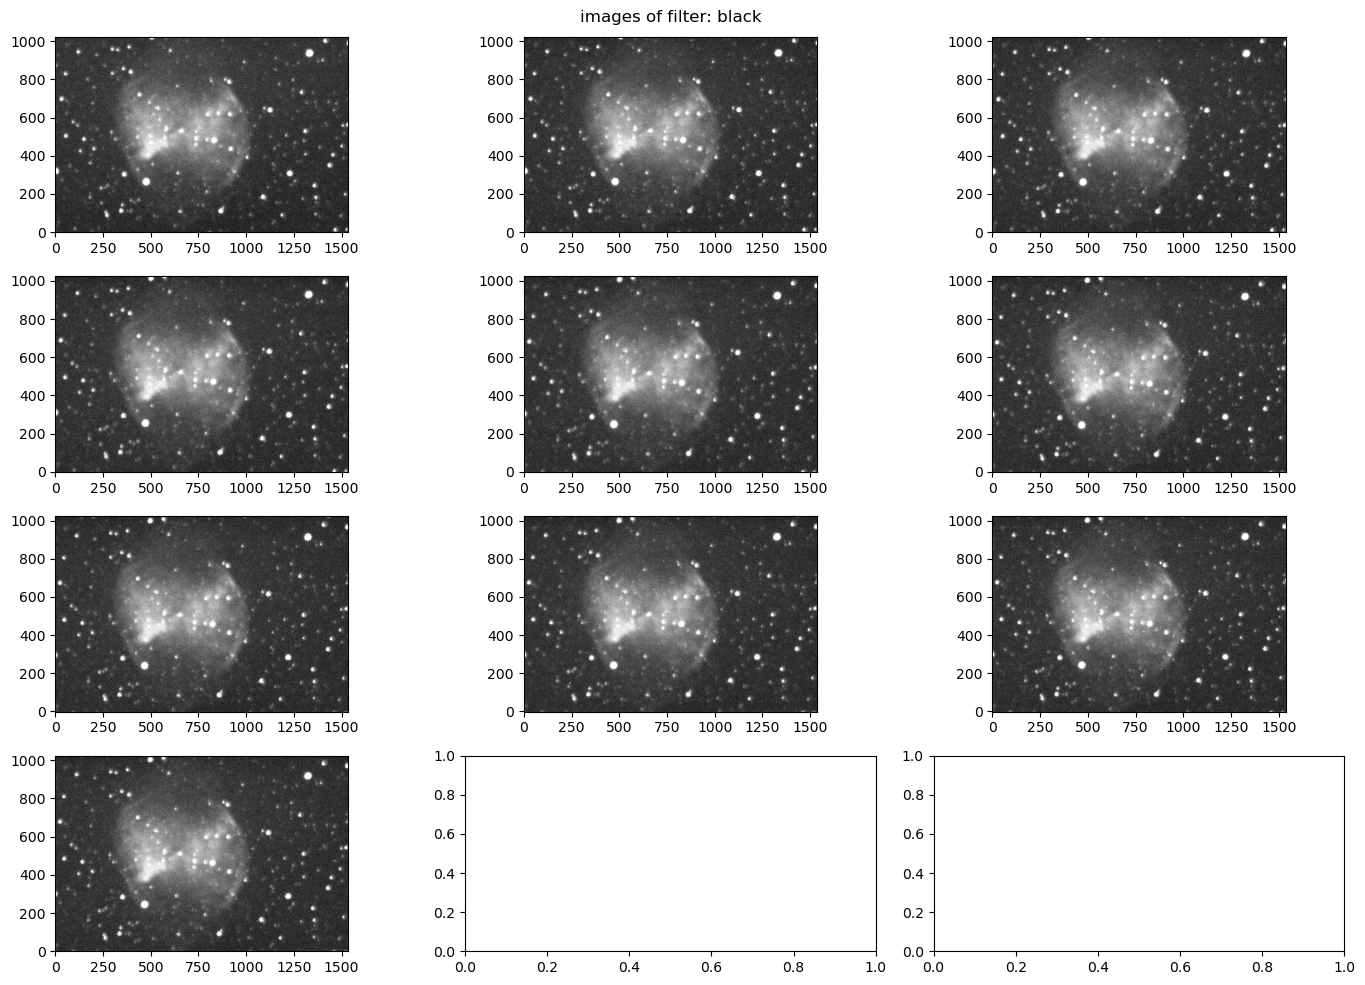

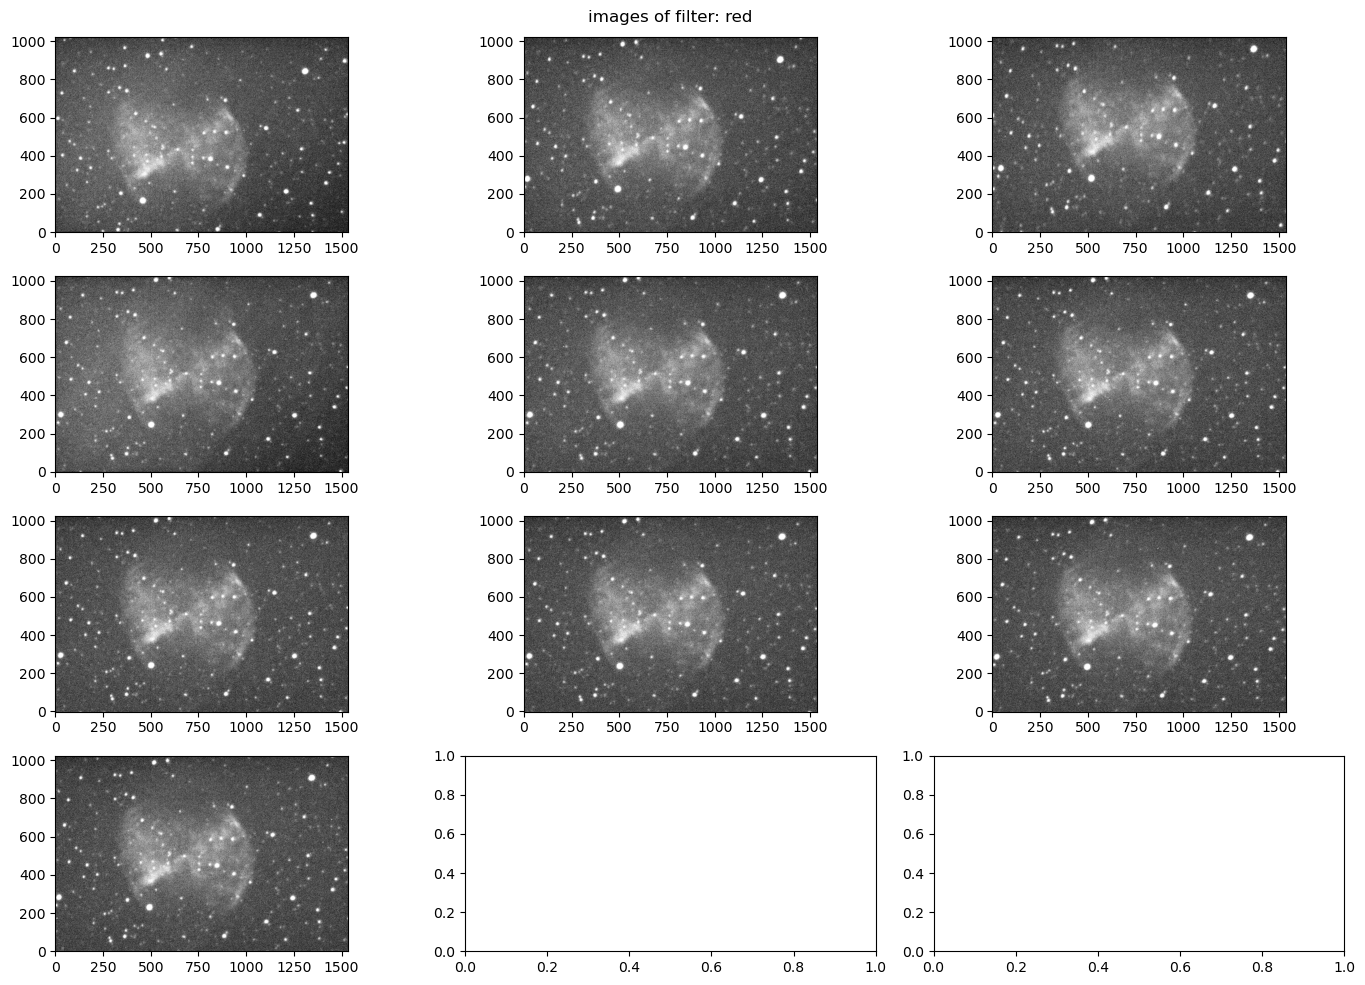

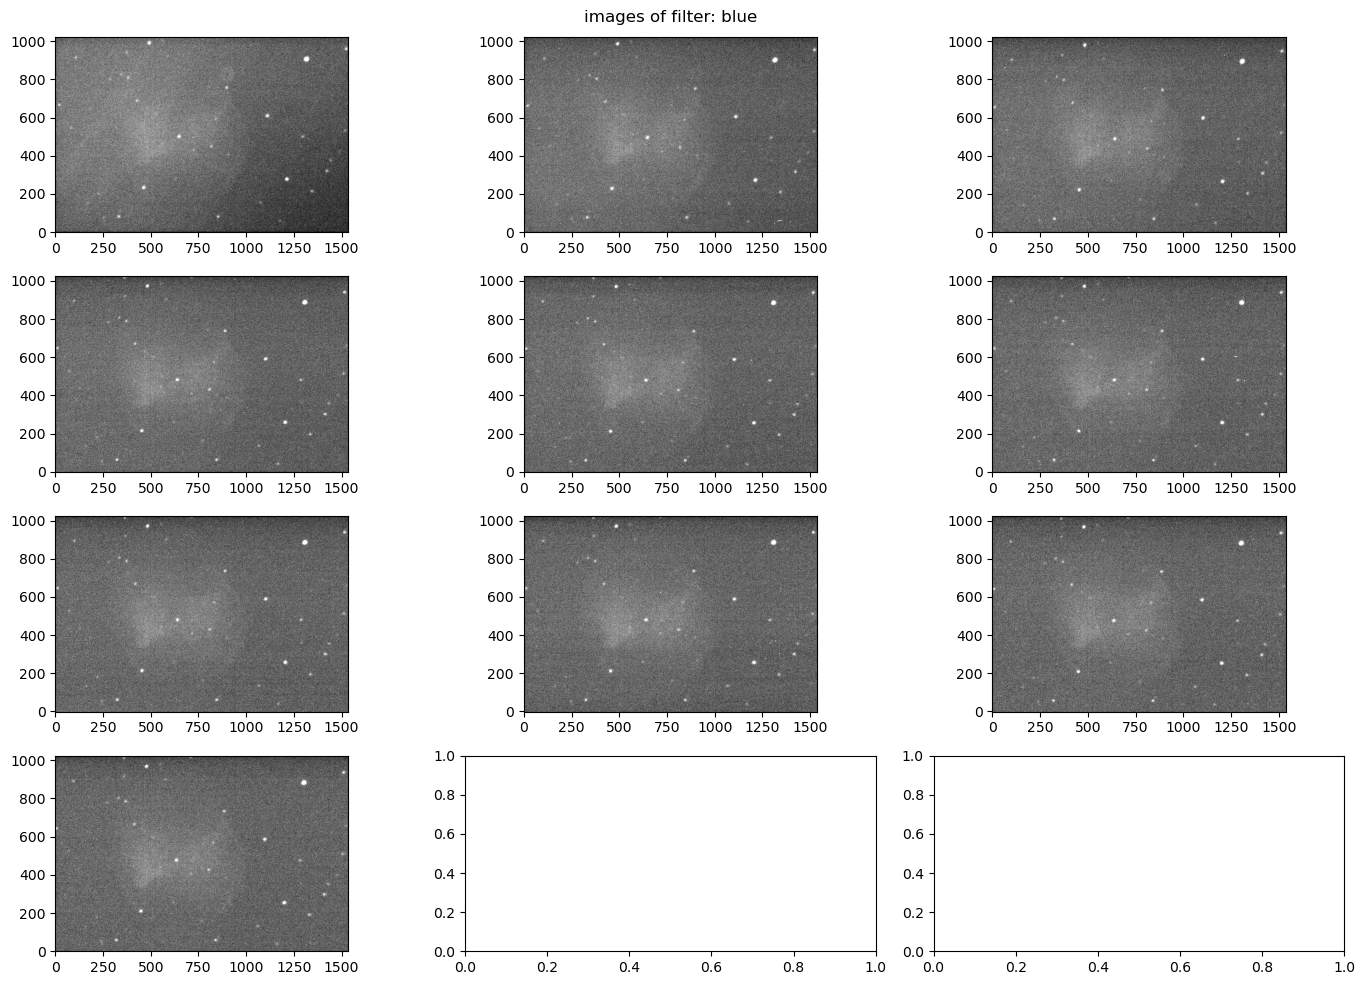

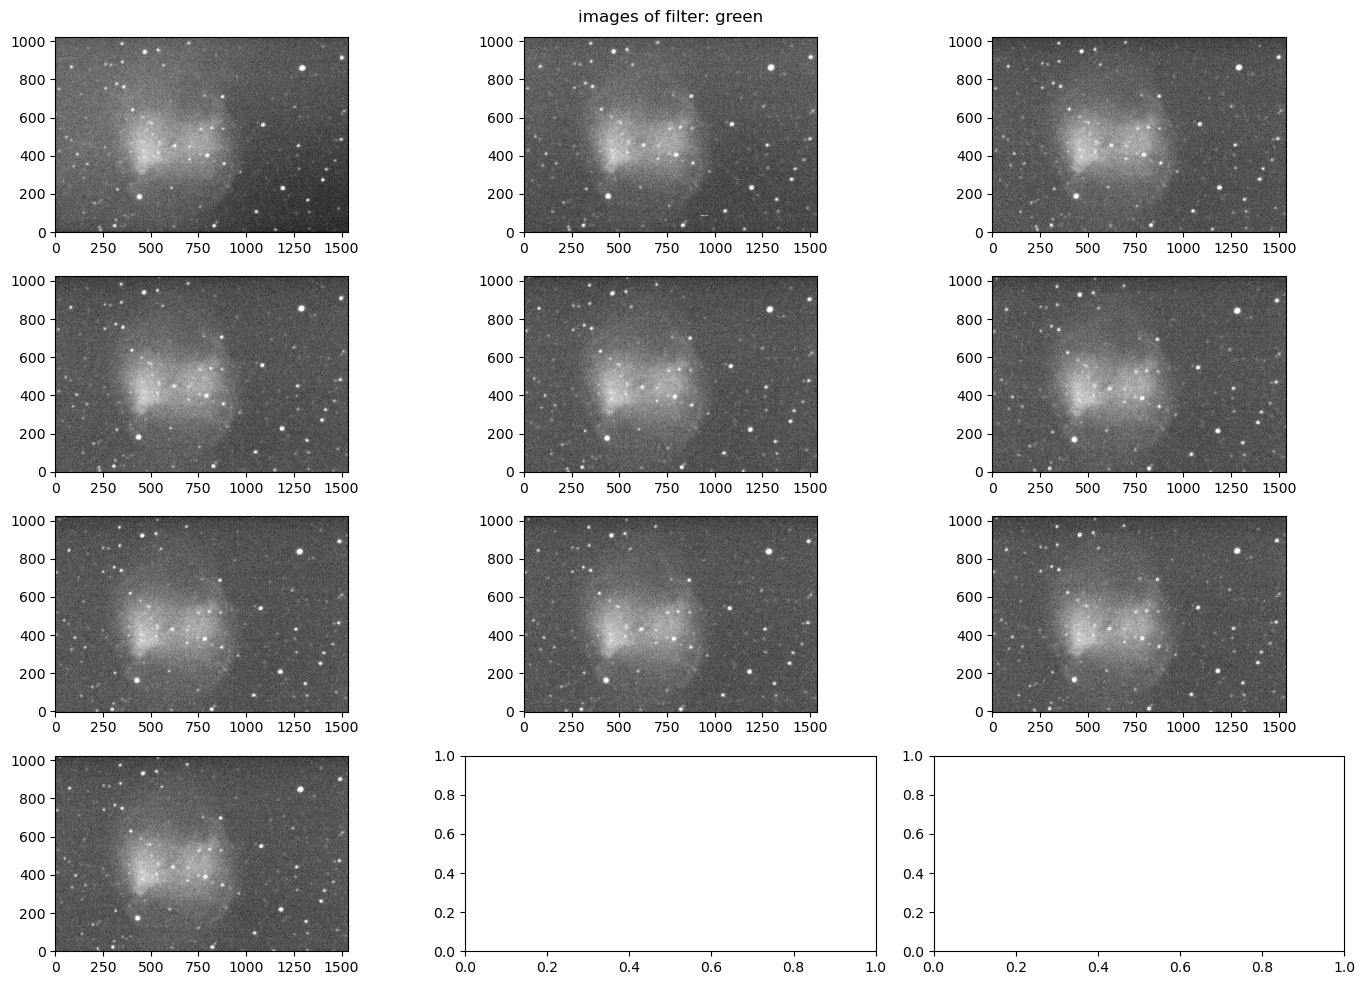

In [173]:
#seperate data in filters into dictionary
dir = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\m27"
filters = ["black","red","blue","green"]

data = {}
for filter in filters:
    data[filter] = []

for filter in filters:
    files = os.listdir(dir + r"\\" + filter)
    for file in files:
        if "calibrated" in file:
            data[filter].append(fits.open(dir + r"\\" + filter + r"\\" + file))

#print(data)

for filter in filters:
    l = len(data[filter]) / 3
    if type(l) == float:
        l = int(l) + 1 
    fig,axs = plt.subplots(l,3,figsize = (14,10))
    for i in range(len(data[filter])):
        m = int(i/3)
        n = i - 3* int(i/3)
        image = data[filter][i][0].data
        lo,up = np.percentile(image,5),np.percentile(image,99)
        axs[m][n].imshow(image,cmap='gray',clim=(lo,up),origin="lower")
    fig.suptitle("images of filter: " + filter)
    fig.tight_layout()
    plt.show()

**IMAGE ALIGNMENT**'

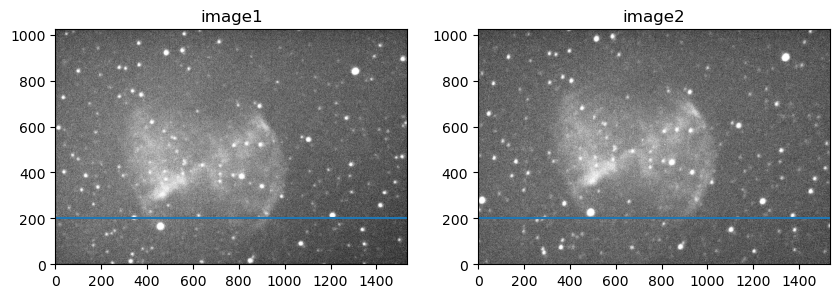

In [174]:
#IMAGE ALIGNMENT -- first try with two red filtered images

im1 = data["red"][0][0].data
im2 = data["red"][1][0].data

fig, axs = plt.subplots(1,2,figsize=(10,6))
lo,up = np.percentile(im1,1),np.percentile(im1,99)
axs[0].imshow(im1,cmap='gray',clim=(lo,up),origin="lower")
axs[0].hlines(y=200,xmin=0,xmax=len(im1[0])-1)
axs[0].set_title("image1")
lo,up = np.percentile(im2,1),np.percentile(im2,99)
axs[1].imshow(im2,cmap='gray',clim=(lo,up),origin="lower")
axs[1].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
axs[1].set_title("image2")
plt.show()




[621.67332005 218.81024646] [651.2384418  275.07099858]
[619.53467063 209.62598002] [649.52480056 269.58193614]


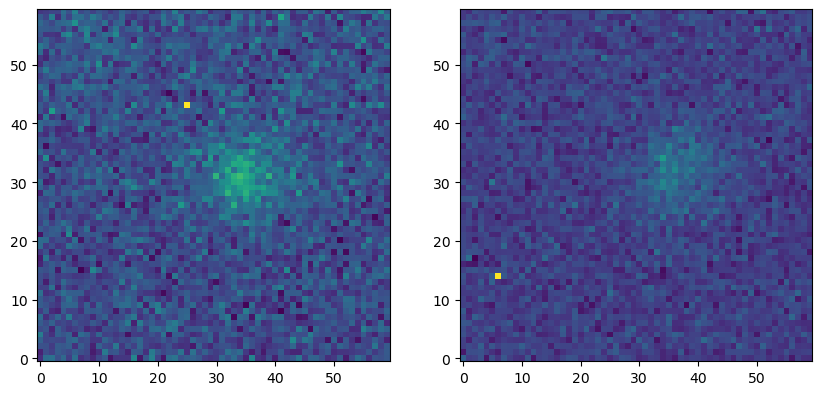

In [175]:
from photutils.centroids import centroid_com, centroid_2dg  #load centroid libraries

#rough positions of reference
pos1 = (620,210)
pos2 = (650,270)

#cut subimages from main images
subim1 = im1[pos1[1]-30:pos1[1]+30,pos1[0]-30:pos1[0]+30]
subim2 = im2[pos2[1]-30:pos2[1]+30,pos2[0]-30:pos2[0]+30]

#get centers of the object
center1,center2 = centroid_2dg(subim1)+pos1-[30,30],centroid_2dg(subim2)+pos2-[30,30] #gaussian fit
ccenter1,ccenter2 = centroid_com(subim1)+pos1-[30,30],centroid_com(subim2)+pos2-[30,30] #center of mass (intensity)
print(center1,center2)
print(ccenter1,ccenter2)


fig, axs = plt.subplots(1,2,figsize=(10,6))
axs[0].imshow(subim1,origin="lower")
axs[1].imshow(subim2,origin="lower")
plt.show()


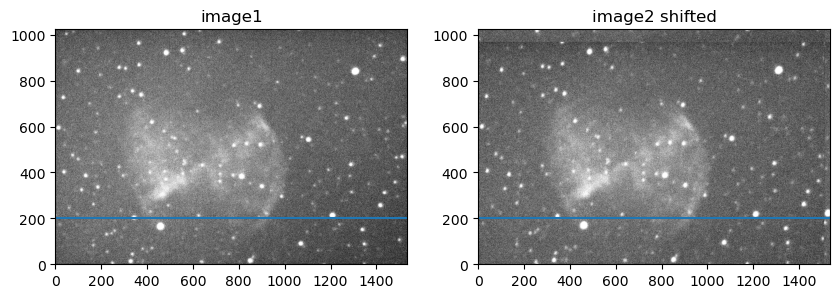

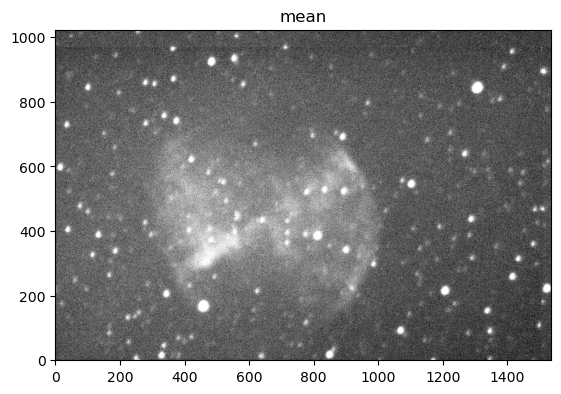

In [176]:
#apply shift to second image
im2_subshift = np.roll(im2,-int(np.round(center2[1]-center1[1])),axis=0) #shift in y
im2_shifted = np.roll(im2_subshift,-int(np.round(center2[0]-center1[0])),axis=1) #shift in x

fig, axs = plt.subplots(1,2,figsize=(10,6))
lo,up = np.percentile(im1,1),np.percentile(im1,99)
axs[0].imshow(im1,cmap='gray',clim=(lo,up),origin="lower")
axs[0].hlines(y=200,xmin=0,xmax=len(im1[0])-1)
axs[0].set_title("image1")
lo,up = np.percentile(im2_shifted,1),np.percentile(im2_shifted,99)
axs[1].imshow(im2_shifted,cmap='gray',clim=(lo,up),origin="lower")
axs[1].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
axs[1].set_title("image2 shifted")
plt.show()

im_mean = (im1 + im2_shifted)/2
lo,up = np.percentile(im_mean,1),np.percentile(im_mean,99)
plt.imshow(im_mean,cmap='gray',clim=(lo,up),origin="lower")
plt.title("mean")
plt.show()




In [177]:
#image alignment as single function
def align_gauss(im1,im2,pos1,pos2,plot=False):
    #cut subimages from main images
    subim1 = im1[pos1[1]-30:pos1[1]+30,pos1[0]-30:pos1[0]+30]
    subim2 = im2[pos2[1]-30:pos2[1]+30,pos2[0]-30:pos2[0]+30]

    if plot == True:
        fig, axs = plt.subplots(1,2,figsize=(10,6))
        lo,up = np.percentile(im1,1),np.percentile(im1,99)
        axs[0].imshow(im1,cmap='gray',clim=(lo,up),origin="lower")
        axs[0].hlines(y=200,xmin=0,xmax=len(im1[0])-1)
        axs[0].set_title("image1")
        lo,up = np.percentile(im2,1),np.percentile(im2,99)
        axs[1].imshow(im2,cmap='gray',clim=(lo,up),origin="lower")
        axs[1].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
        axs[1].set_title("image2")
        plt.show()

    #get centers of the object
    center1,center2 = centroid_2dg(subim1)+pos1-[30,30],centroid_2dg(subim2)+pos2-[30,30] #gaussian fit
    if plot==True:
        fig, axs = plt.subplots(1,2,figsize=(10,6))
        axs[0].imshow(subim1,origin="lower")
        axs[1].imshow(subim2,origin="lower")
        plt.show()

    #apply shift to second image
    im2_subshift = np.roll(im2,-int(np.round(center2[1]-center1[1])),axis=0) #shift in y
    im2_shifted = np.roll(im2_subshift,-int(np.round(center2[0]-center1[0])),axis=1) #shift in x

    if plot==True:
        fig, axs = plt.subplots(1,2,figsize=(10,6))
        lo,up = np.percentile(im1,1),np.percentile(im1,99)
        axs[0].imshow(im1,cmap='gray',clim=(lo,up),origin="lower")
        axs[0].hlines(y=200,xmin=0,xmax=len(im1[0])-1)
        axs[0].set_title("image1")
        lo,up = np.percentile(im2_shifted,1),np.percentile(im2_shifted,99)
        axs[1].imshow(im2_shifted,cmap='gray',clim=(lo,up),origin="lower")
        axs[1].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
        axs[1].set_title("image2 shifted")
        plt.show()

        im_mean = (im1 + im2_shifted)/2
        lo,up = np.percentile(im_mean,1),np.percentile(im_mean,99)
        plt.imshow(im_mean,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("mean")
        plt.show()

    return im2_shifted #return shifted second image

    
    

**COLOR IMAGE** (out of 3 single rgb images)

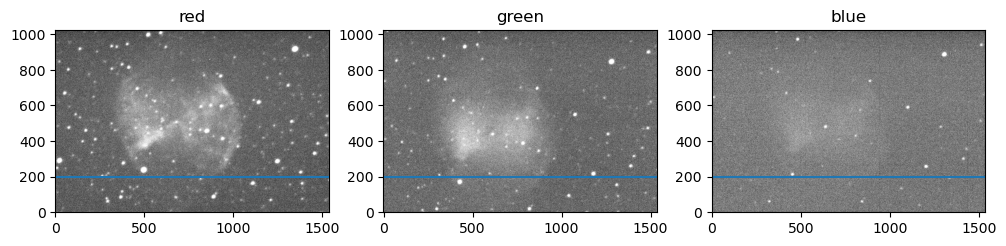

In [178]:
#align images
red = data["red"][8][0].data
green = data["green"][8][0].data
blue = data["blue"][8][0].data

fig, axs = plt.subplots(1,3,figsize=(12,8))
lo,up = np.percentile(red,1),np.percentile(red,99)
axs[0].imshow(red,cmap='gray',clim=(lo,up),origin="lower")
axs[0].hlines(y=200,xmin=0,xmax=len(im1[0])-1)
axs[0].set_title("red")
lo,up = np.percentile(green,1),np.percentile(green,99)
axs[1].imshow(green,cmap='gray',clim=(lo,up),origin="lower")
axs[1].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
axs[1].set_title("green")
lo,up = np.percentile(blue,1),np.percentile(blue,99)
axs[2].imshow(blue,cmap='gray',clim=(lo,up),origin="lower")
axs[2].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
axs[2].set_title("blue")
plt.show()




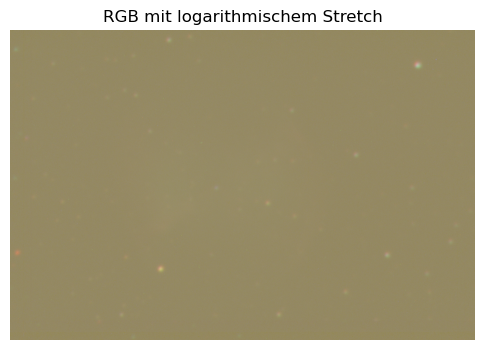

In [180]:
pos_red = (500,230)
pos_green = (420,180)
pos_blue = (460,205)

#align images
green_aligned = align_gauss(red,green,pos_red,pos_green, plot=False) #align green to red
blue_aligned = align_gauss(red,blue,pos_red,pos_blue,plot=False) #align blue to red

#need log scale in order to see anything
def scale_log(channel, vmin=None, vmax=None):
    channel = np.array(channel, dtype=float)
    if vmin is None:
        vmin = channel[channel > 0].min() 
    if vmax is None:
        vmax = channel.max()
    # log stretch
    scaled = (np.log(channel.clip(vmin, vmax)) - np.log(vmin)) / (np.log(vmax) - np.log(vmin))
    return scaled

vmin = min(red[red>0].min(), green_aligned[green_aligned>0].min(), blue_aligned[blue_aligned>0].min())
vmax = max(red.max(), green.max(), blue.max())

r_scaled = scale_log(red,vmin=vmin,vmax=vmax)
g_scaled = scale_log(green_aligned,vmin=vmin,vmax=vmax)
b_scaled = scale_log(blue_aligned,vmin=vmin,vmax=vmax)

rgb_log = np.dstack((r_scaled, g_scaled, b_scaled))

plt.figure(figsize=(6,6))
plt.imshow(rgb_log, origin="lower")
plt.title("RGB mit logarithmischem Stretch")
plt.axis("off")
plt.show()

